In [3]:
import importlib
import src.modeling

importlib.reload(src.modeling)

from src.modeling import make_preprocessor, make_models

print("Imports successful!")

Imports successful!


In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
import time

from pathlib import Path

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing import build_features
from src.modeling import make_preprocessor, make_models
from src.evaluation import regression_metrics

DATA_DIR = PROJECT_ROOT / "data"

df = pd.read_csv(
    DATA_DIR / "train-test.csv",
    parse_dates=["date"]
)

print("Dataset:", df.shape)


Dataset: (48000, 14)


In [5]:

validation_months = [
    "2025-08-01",
    "2025-09-01",
    "2025-10-01"
]

experiments = []


In [6]:

for month in validation_months:

    start = pd.Timestamp(month)
    end = start + pd.DateOffset(months=1)

    # 1. Chronological split
    train_raw = df[df["date"] < start].copy()

    holdout_raw = df[
        (df["date"] >= start) &
        (df["date"] < end)
    ].copy()

    assert train_raw["date"].max() < holdout_raw["date"].min()

    # 2. Feature engineering
    X_train = build_features(train_raw)
    y_train = train_raw["posted_rate"]

    X_holdout = build_features(holdout_raw)
    y_holdout = holdout_raw["posted_rate"]

    # 3. Fit preprocessing ONLY on training data
    preprocessor = make_preprocessor(X_train)

    X_train_ready = preprocessor.fit_transform(X_train)
    X_holdout_ready = preprocessor.transform(X_holdout)

    print(f"\nHoldout month: {start.strftime('%Y-%m')}")
    print("Training loads:", len(train_raw))
    print("Holdout loads:", len(holdout_raw))

    # 4. Train and evaluate each model
    for name, model in make_models().items():

        start_time = time.perf_counter()

        model.fit(X_train_ready, y_train)

        predictions = model.predict(X_holdout_ready)

        training_seconds = (
            time.perf_counter() - start_time
        )

        metrics = regression_metrics(
            y_holdout,
            predictions
        )

        experiments.append({
            "Month": start.strftime("%Y-%m"),
            "Model": name,
            "Train Rows": len(train_raw),
            "Holdout Rows": len(holdout_raw),
            "Seconds": round(training_seconds, 2),
            **metrics
        })

        print(
            f"{name}: "
            f"MAE=${metrics['MAE']:.2f}, "
            f"WAPE={metrics['WAPE (%)']:.2f}%"
        )



Holdout month: 2025-08
Training loads: 33718
Holdout loads: 4759


/Users/ahmedali/spotter-freight-rate-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


LightGBM: MAE=$94.64, WAPE=4.05%
XGBoost: MAE=$99.46, WAPE=4.25%
CatBoost: MAE=$99.17, WAPE=4.24%

Holdout month: 2025-09
Training loads: 38477
Holdout loads: 4670


/Users/ahmedali/spotter-freight-rate-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


LightGBM: MAE=$108.15, WAPE=4.49%
XGBoost: MAE=$110.07, WAPE=4.57%
CatBoost: MAE=$108.92, WAPE=4.53%

Holdout month: 2025-10
Training loads: 43147
Holdout loads: 4853


/Users/ahmedali/spotter-freight-rate-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


LightGBM: MAE=$112.70, WAPE=4.74%
XGBoost: MAE=$111.94, WAPE=4.71%
CatBoost: MAE=$109.60, WAPE=4.61%


In [7]:

results_df = pd.DataFrame(experiments)

display(
    results_df.sort_values(
        ["Month", "MAE"]
    )
)


,Month,Model,Train Rows,Holdout Rows,Seconds,MAE,RMSE,WAPE (%),R2
0,2025-08,LightGBM,33718,4759,2.47,94.64,614.48,4.05,0.8264
2,2025-08,CatBoost,33718,4759,0.69,99.17,614.69,4.24,0.8263
1,2025-08,XGBoost,33718,4759,1.52,99.46,614.89,4.25,0.8262
3,2025-09,LightGBM,38477,4670,2.43,108.15,617.55,4.49,0.8357
5,2025-09,CatBoost,38477,4670,0.70,108.92,617.60,4.53,0.8356
4,2025-09,XGBoost,38477,4670,1.67,110.07,618.63,4.57,0.8351
8,2025-10,CatBoost,43147,4853,0.80,109.60,647.29,4.61,0.8207
7,2025-10,XGBoost,43147,4853,1.78,111.94,647.75,4.71,0.8204
6,2025-10,LightGBM,43147,4853,2.49,112.70,647.35,4.74,0.8206


In [8]:

summary = (
    results_df.groupby("Model", as_index=False)
    .agg(
        average_MAE=("MAE", "mean"),
        worst_month_MAE=("MAE", "max"),
        average_RMSE=("RMSE", "mean"),
        average_WAPE=("WAPE (%)", "mean"),
        average_R2=("R2", "mean"),
        average_seconds=("Seconds", "mean")
    )
    .round(2)
    .sort_values("average_MAE")
)

display(summary)


,Model,average_MAE,worst_month_MAE,average_RMSE,average_WAPE,average_R2,average_seconds
1,LightGBM,105.16,112.70,626.46,4.43,0.83,2.46
0,CatBoost,105.90,109.60,626.53,4.46,0.83,0.73
2,XGBoost,107.16,111.94,627.09,4.51,0.83,1.66


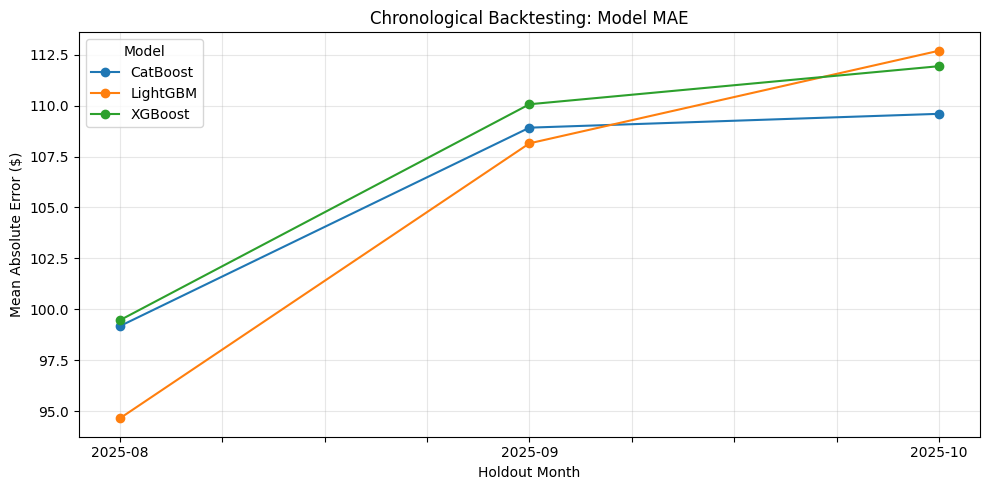

In [9]:

monthly_mae = results_df.pivot(
    index="Month",
    columns="Model",
    values="MAE"
)

monthly_mae.plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

plt.title("Chronological Backtesting: Model MAE")
plt.xlabel("Holdout Month")
plt.ylabel("Mean Absolute Error ($)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [10]:

REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(exist_ok=True)

results_df.to_csv(
    REPORTS_DIR / "model_comparison.csv",
    index=False
)

print("Experiment results saved!")


Experiment results saved!


In [11]:

feature_experiments = []

feature_sets = {
    "Common": False,
    "Full": True
}

for month in validation_months:

    start = pd.Timestamp(month)
    end = start + pd.DateOffset(months=1)

    train_raw = df[df["date"] < start].copy()

    holdout_raw = df[
        (df["date"] >= start) &
        (df["date"] < end)
    ].copy()

    for feature_name, include_optional in feature_sets.items():

        X_train = build_features(
            train_raw,
            include_optional=include_optional
        )

        X_holdout = build_features(
            holdout_raw,
            include_optional=include_optional
        )

        y_train = train_raw["posted_rate"]
        y_holdout = holdout_raw["posted_rate"]

        preprocessor = make_preprocessor(X_train)

        X_train_ready = preprocessor.fit_transform(X_train)
        X_holdout_ready = preprocessor.transform(X_holdout)

        for model_name in ["LightGBM", "CatBoost"]:

            model = make_models()[model_name]

            model.fit(X_train_ready, y_train)

            predictions = model.predict(X_holdout_ready)

            metrics = regression_metrics(
                y_holdout, predictions
            )

            feature_experiments.append({
                "Month": month[:7],
                "Model": model_name,
                "Features": feature_name,
                "MAE": metrics["MAE"],
                "RMSE": metrics["RMSE"]
            })

ablation_df = pd.DataFrame(feature_experiments)

display(ablation_df)


/Users/ahmedali/spotter-freight-rate-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/ahmedali/spotter-freight-rate-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/ahmedali/spotter-freight-rate-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/ahmedali/spotter-freight-rate-prediction/.venv/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/ahmedali/spotter-freight-rate-prediction/.venv/lib/python3.9/site-pac

,Month,Model,Features,MAE,RMSE
0,2025-08,LightGBM,Common,94.64,614.48
1,2025-08,CatBoost,Common,99.17,614.69
2,2025-08,LightGBM,Full,123.71,617.43
3,2025-08,CatBoost,Full,102.96,614.39
4,2025-09,LightGBM,Common,108.15,617.55
5,2025-09,CatBoost,Common,108.92,617.60
6,2025-09,LightGBM,Full,108.22,618.83
7,2025-09,CatBoost,Full,114.19,620.12
8,2025-10,LightGBM,Common,112.70,647.35
9,2025-10,CatBoost,Common,109.60,647.29


In [12]:

ablation_summary = (
    ablation_df
    .groupby(["Model", "Features"])
    .agg(
        average_MAE=("MAE", "mean"),
        worst_MAE=("MAE", "max"),
        average_RMSE=("RMSE", "mean")
    )
    .round(2)
    .sort_values("average_MAE")
)

display(ablation_summary)


average_MAE  worst_MAE  average_RMSE
Model    Features                                      
LightGBM Common         105.16     112.70        626.46
CatBoost Common         105.90     109.60        626.53
         Full           111.19     116.41        627.08
LightGBM Full           115.93     123.71        627.87